# Assignment 1: Uber Fare Prediction (Linear Regression & Random Forest)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## 1. Pre-process the dataset

In [2]:
data = pd.read_csv("uber.csv")
print(data.shape)
data.head()

(200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


In [4]:
# Drop columns that are not useful for prediction
data = data.drop(['Unnamed: 0', 'key'], axis=1)
print(data.isnull().sum())

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [5]:
# Fill the (only) missing values with the median
for col in ['dropoff_longitude', 'dropoff_latitude']:
    data[col] = data[col].fillna(data[col].median())
print(data.isnull().sum().sum(), "missing values left")

0 missing values left


In [6]:
# Convert pickup_datetime and extract useful time features
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'], errors='coerce')
data = data.assign(hour=data.pickup_datetime.dt.hour,
                   day=data.pickup_datetime.dt.day,
                   month=data.pickup_datetime.dt.month,
                   year=data.pickup_datetime.dt.year,
                   dayofweek=data.pickup_datetime.dt.dayofweek)
data = data.drop('pickup_datetime', axis=1)
data.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3


In [7]:
# Remove clearly invalid records (impossible values, not just statistical outliers)
before = len(data)
data = data[(data.fare_amount > 0) &
            (data.passenger_count.between(1, 6)) &
            (data.pickup_latitude.between(-90, 90)) & (data.dropoff_latitude.between(-90, 90)) &
            (data.pickup_longitude.between(-180, 180)) & (data.dropoff_longitude.between(-180, 180)) &
            (data.pickup_longitude != 0) & (data.dropoff_longitude != 0)].reset_index(drop=True)
print("Rows removed:", before - len(data), "| Rows left:", len(data))

Rows removed: 4682 | Rows left: 195318


In [8]:
# Distance travelled (Haversine formula, vectorised)
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

data['dist_travel_km'] = haversine(data.pickup_longitude, data.pickup_latitude,
                                   data.dropoff_longitude, data.dropoff_latitude)
data[['fare_amount', 'dist_travel_km']].describe()

,fare_amount,dist_travel_km
count,195318.000000,195318.000000
mean,11.352257,4.677400
std,9.804448,88.879842
min,0.010000,0.000000
25%,6.000000,1.255776
50%,8.500000,2.157519
75%,12.500000,3.910972
max,499.000000,8667.693178


## 2. Identify outliers

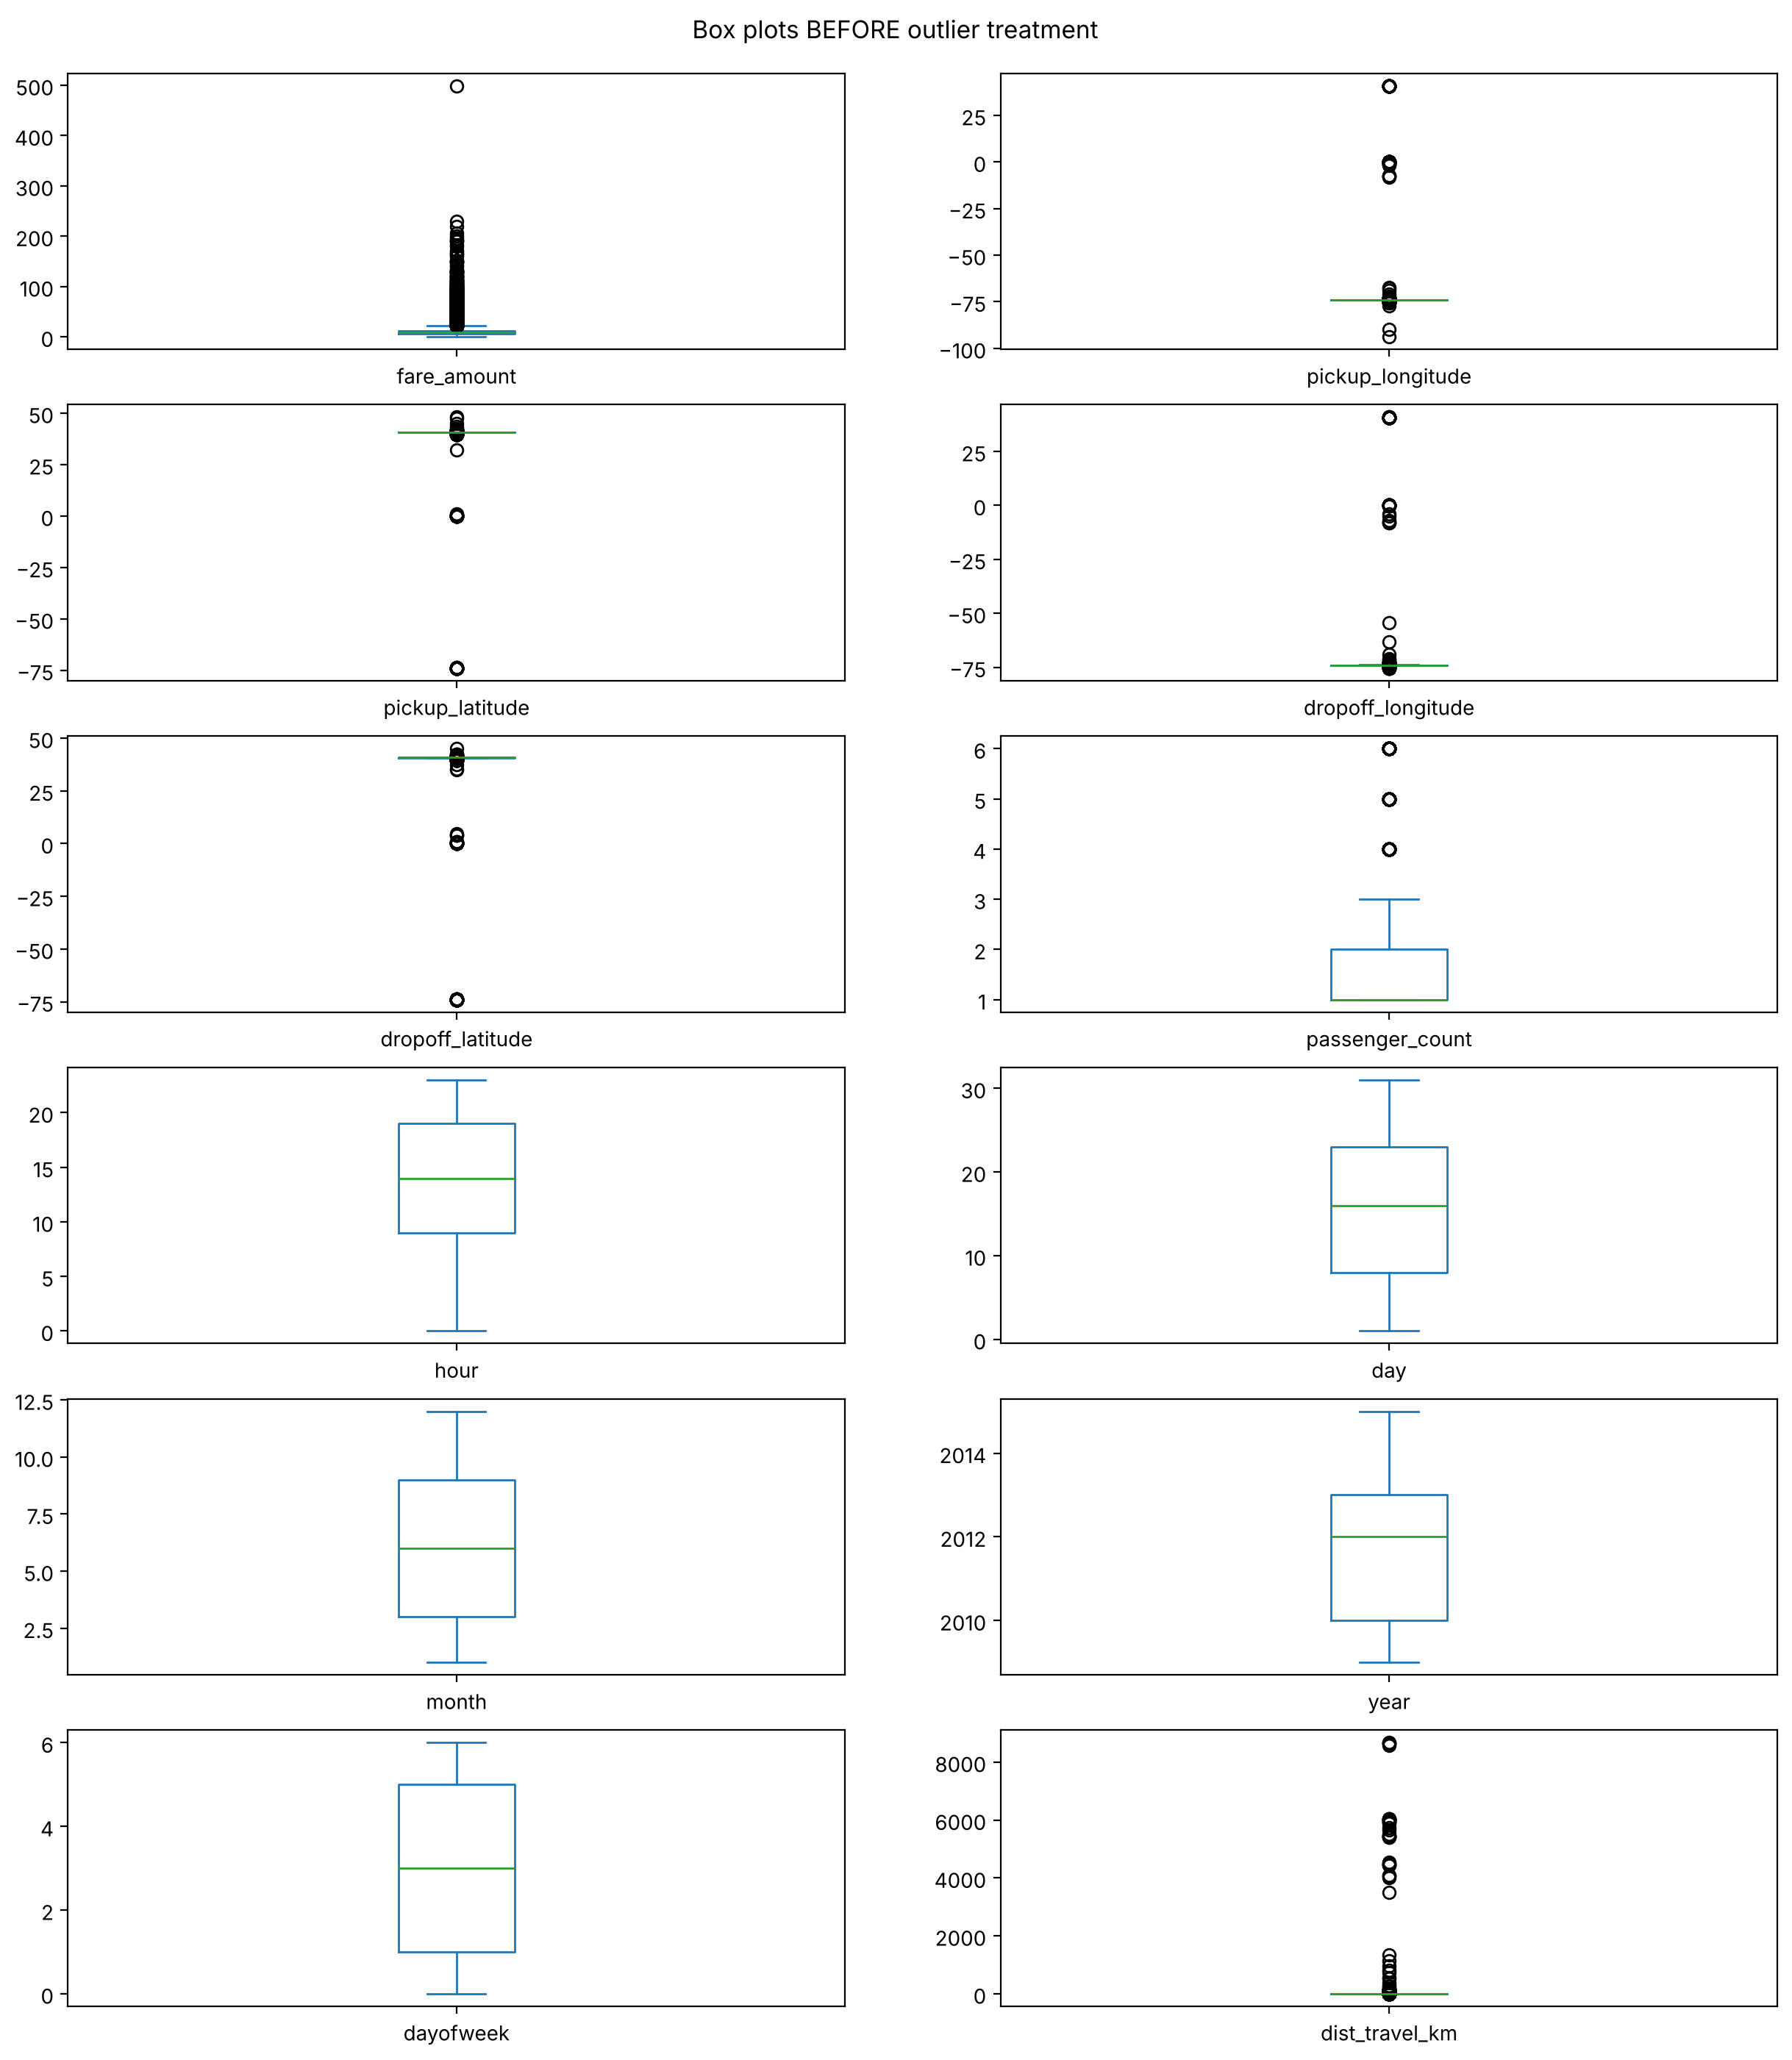

In [9]:
data.plot(kind="box", subplots=True, layout=(7, 2), figsize=(15, 20))
plt.suptitle("Box plots BEFORE outlier treatment", y=0.9)
plt.show()

In [10]:
# IQR method: count outliers in each column
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5*iqr, q3 + 1.5*iqr

for c in data.columns:
    lo, hi = iqr_bounds(data[c])
    print(f"{c:20s} outliers: {((data[c] < lo) | (data[c] > hi)).sum()}")

fare_amount          outliers: 16740
pickup_longitude     outliers: 9885
pickup_latitude      outliers: 6087
dropoff_longitude    outliers: 11055
dropoff_latitude     outliers: 9017
passenger_count      outliers: 22124
hour                 outliers: 0
day                  outliers: 0
month                outliers: 0
year                 outliers: 0
dayofweek            outliers: 0
dist_travel_km       outliers: 16231


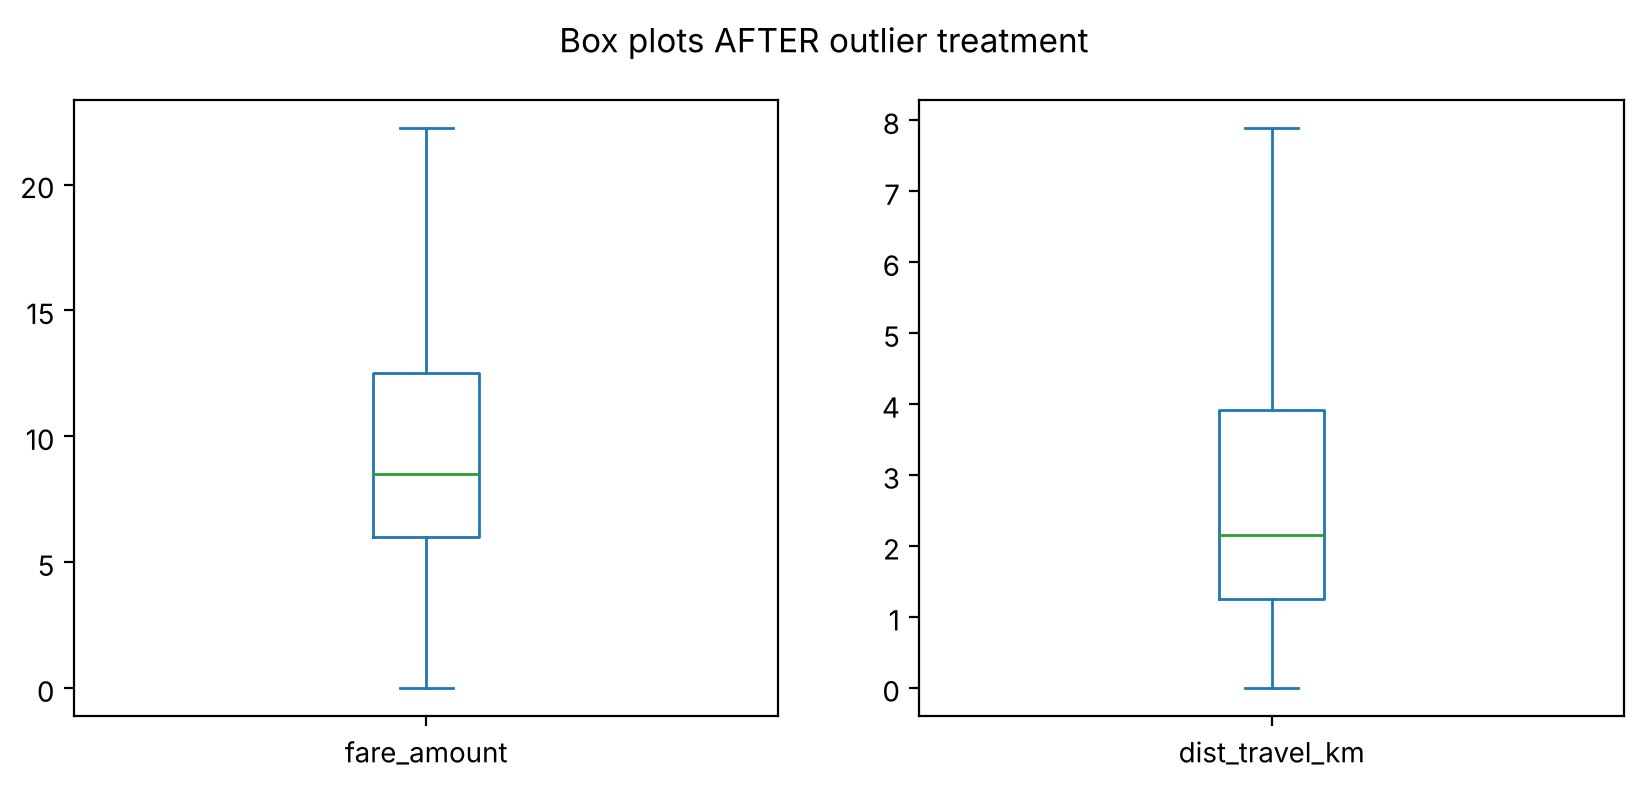

In [11]:
# Treat outliers in the continuous columns that matter (fare and distance) by capping at the IQR whiskers.
# Coordinates / passenger_count / date parts are left as they are (already validated above).
for c in ['fare_amount', 'dist_travel_km']:
    lo, hi = iqr_bounds(data[c])
    data[c] = data[c].clip(lo, hi)

data[['fare_amount', 'dist_travel_km']].plot(kind="box", subplots=True, layout=(1, 2), figsize=(10, 4))
plt.suptitle("Box plots AFTER outlier treatment")
plt.show()

## 3. Check the correlation

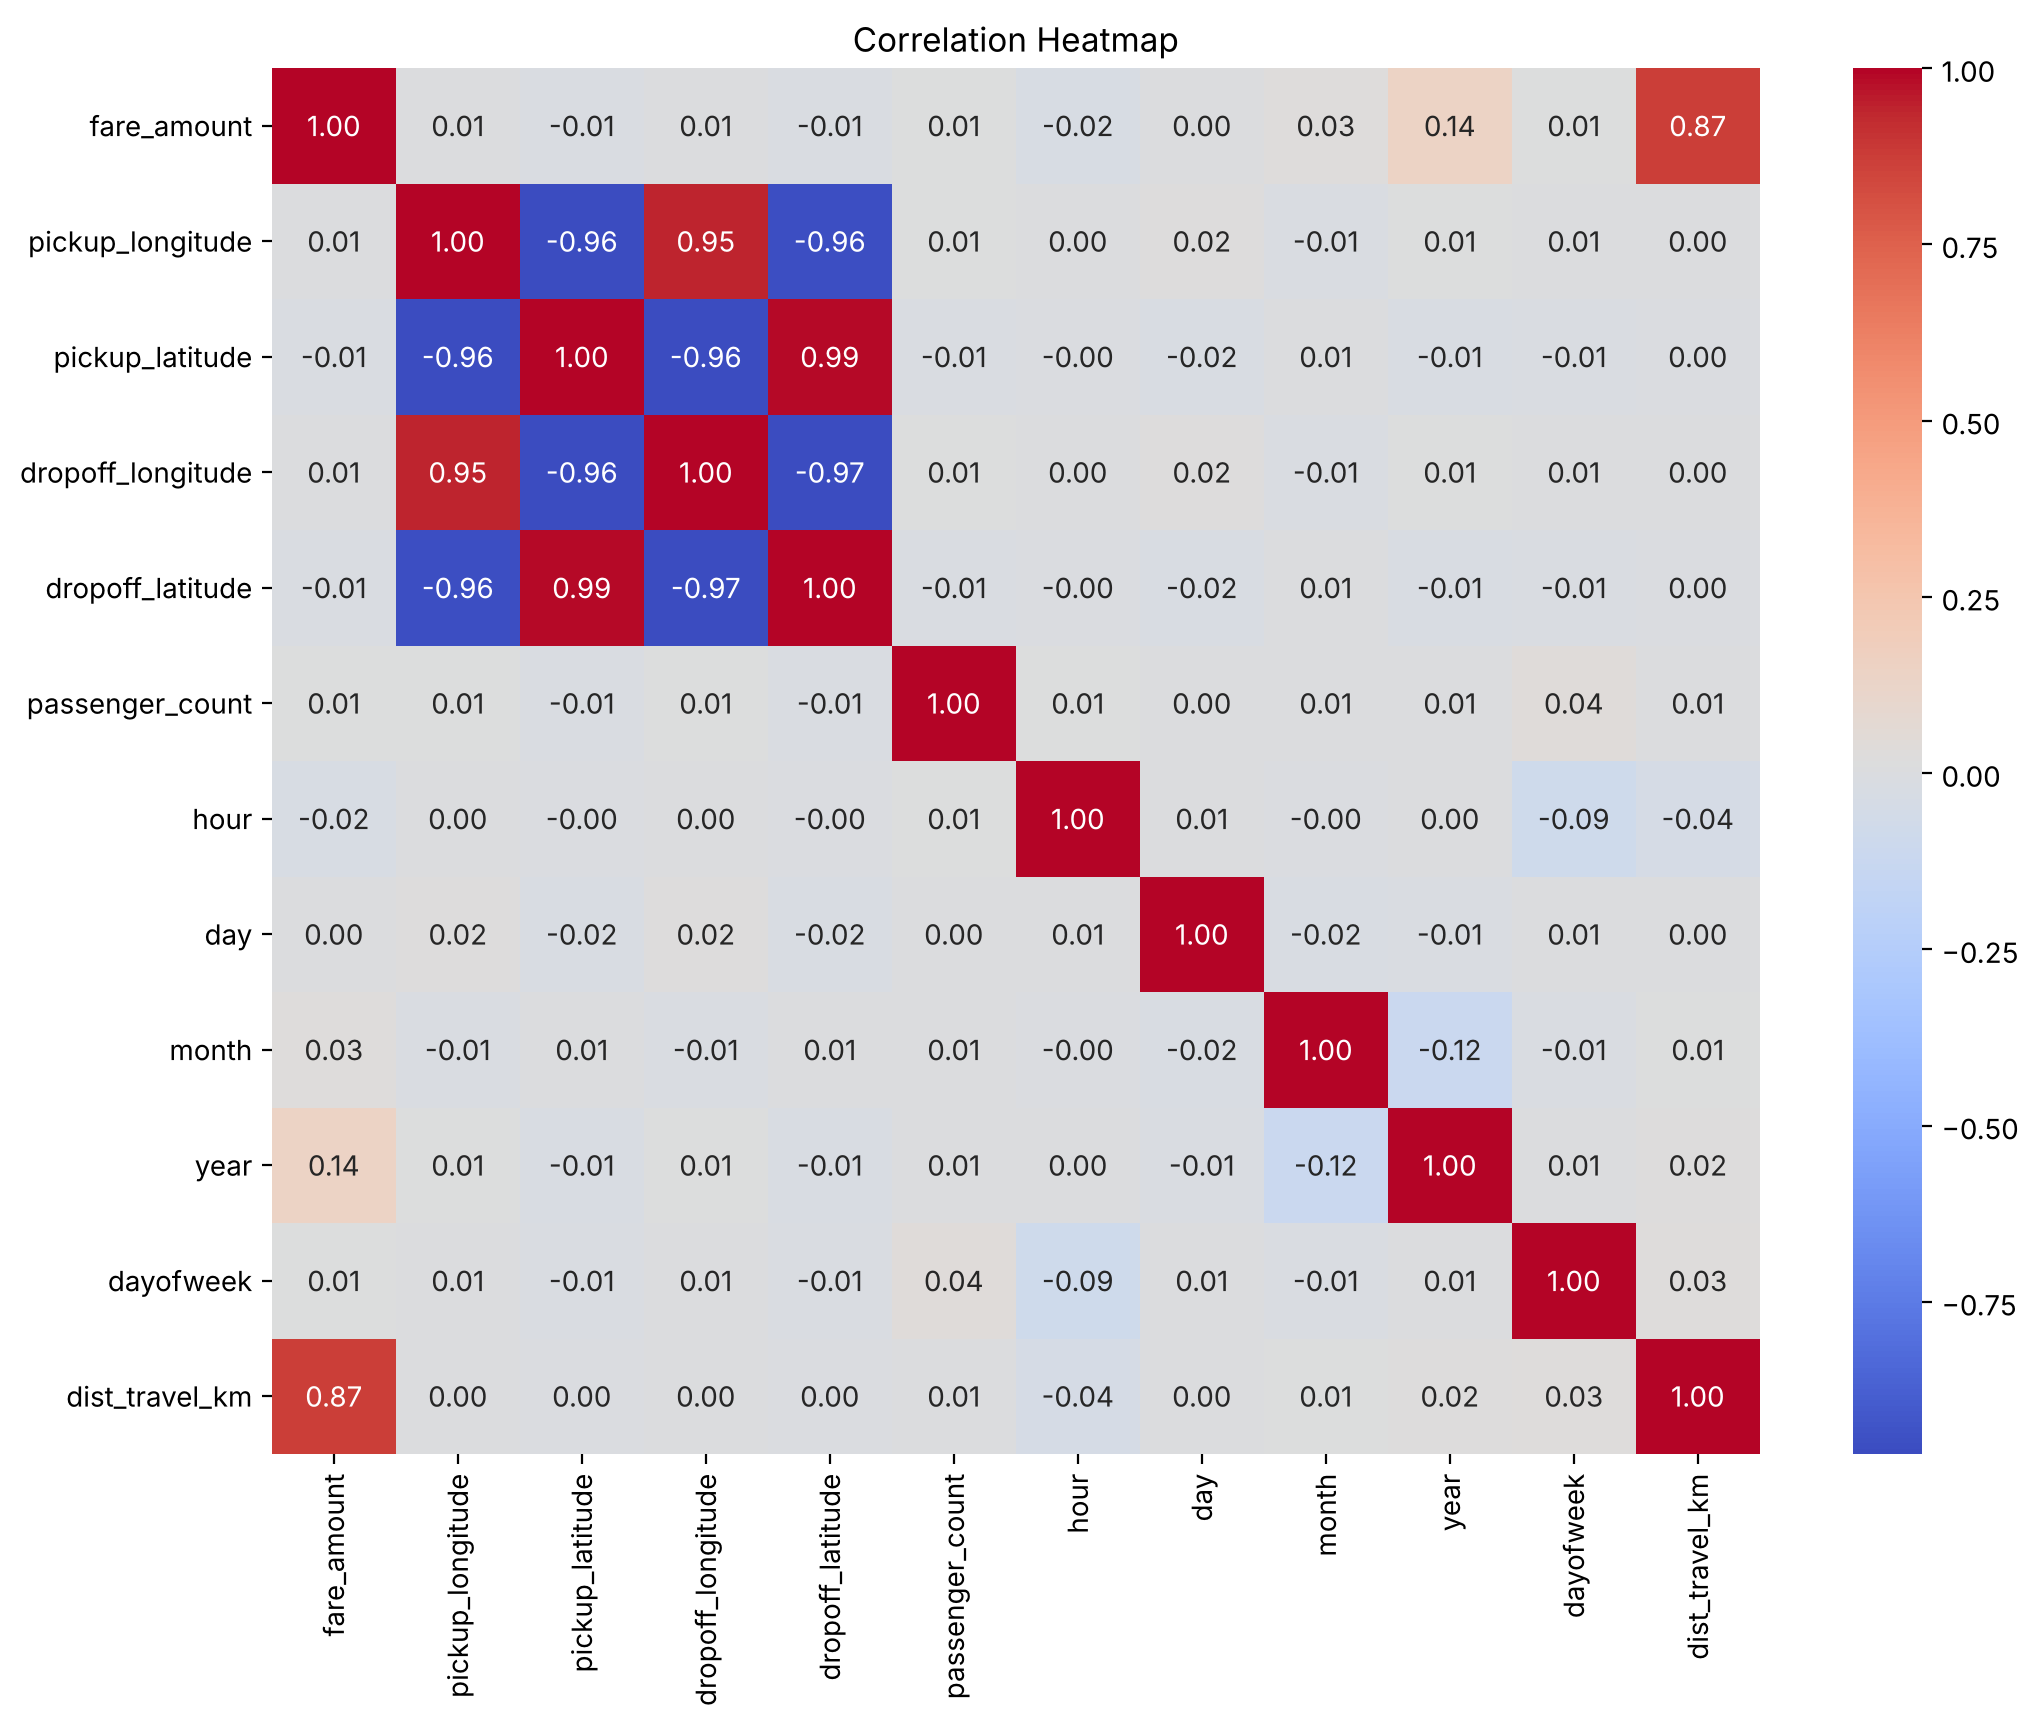

fare_amount          1.000000
dist_travel_km       0.870555
year                 0.141618
month                0.031032
passenger_count      0.013899
dayofweek            0.013144
pickup_longitude     0.009199
dropoff_longitude    0.008849
day                  0.004065
pickup_latitude     -0.007217
dropoff_latitude    -0.007443
hour                -0.023450
Name: fare_amount, dtype: float64


In [12]:
corr = data.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()
print(corr['fare_amount'].sort_values(ascending=False))

## 4. Implement Linear Regression and Random Forest Regression

In [13]:
features = ['pickup_longitude','pickup_latitude','dropoff_longitude','dropoff_latitude',
            'passenger_count','hour','day','month','year','dayofweek','dist_travel_km']
x = data[features]
y = data['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42)
print(X_train.shape, X_test.shape)

(130863, 11) (64455, 11)


In [14]:
# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
print("Intercept:", lr.intercept_)
print(pd.Series(lr.coef_, index=features))

Intercept: -738.7144456730547
pickup_longitude    -0.045417
pickup_latitude     -0.139586
dropoff_longitude   -0.059158
dropoff_latitude     0.016145
passenger_count      0.027774
hour                 0.008400
day                  0.002024
month                0.055474
year                 0.367573
dayofweek           -0.033434
dist_travel_km       2.135079
dtype: float64


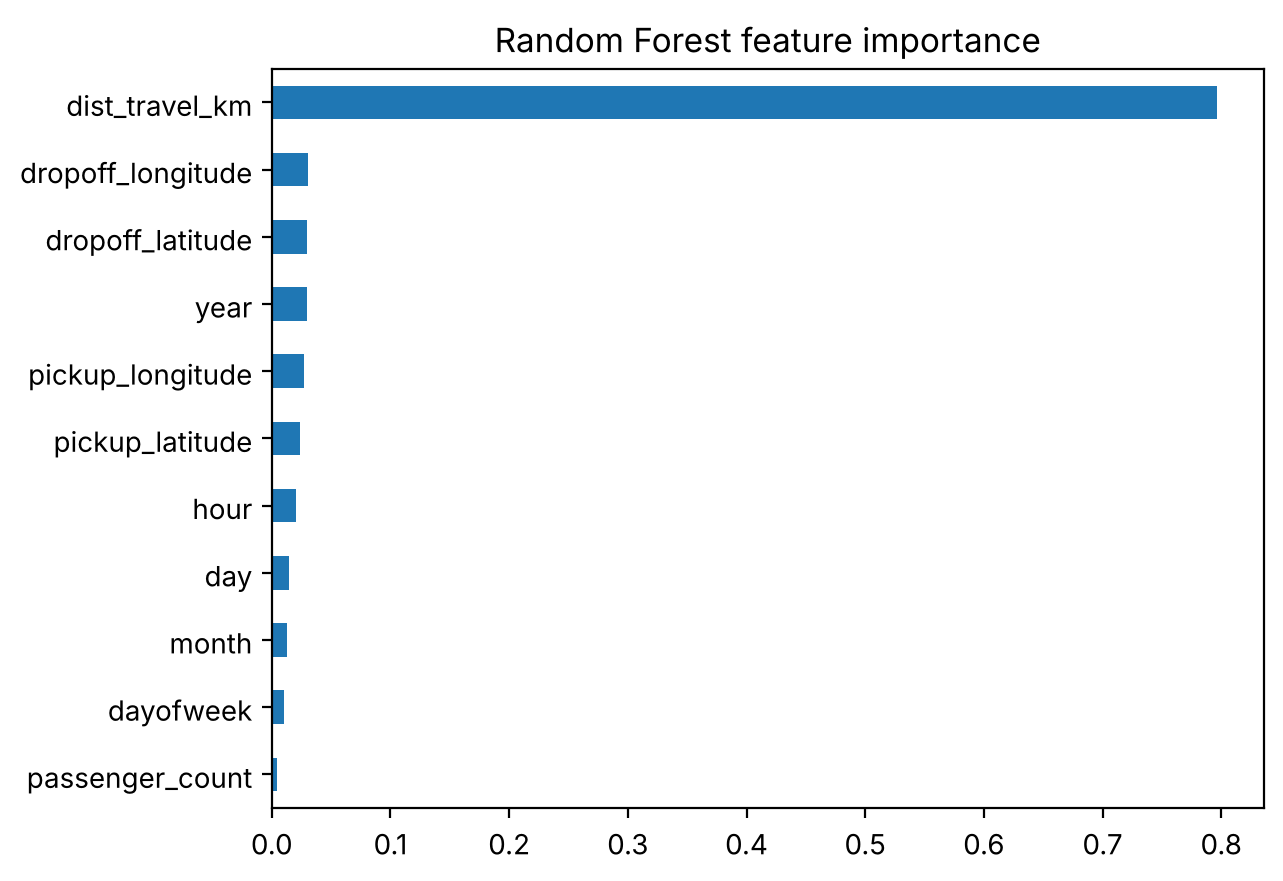

In [15]:
# Random Forest Regression
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
pd.Series(rf.feature_importances_, index=features).sort_values().plot(kind='barh', title="Random Forest feature importance")
plt.show()

## 5. Evaluate and compare the models

                       R2     MAE     MSE    RMSE
Model                                            
Linear Regression  0.7764  1.7284  6.5963  2.5683
Random Forest      0.8374  1.4036  4.7970  2.1902


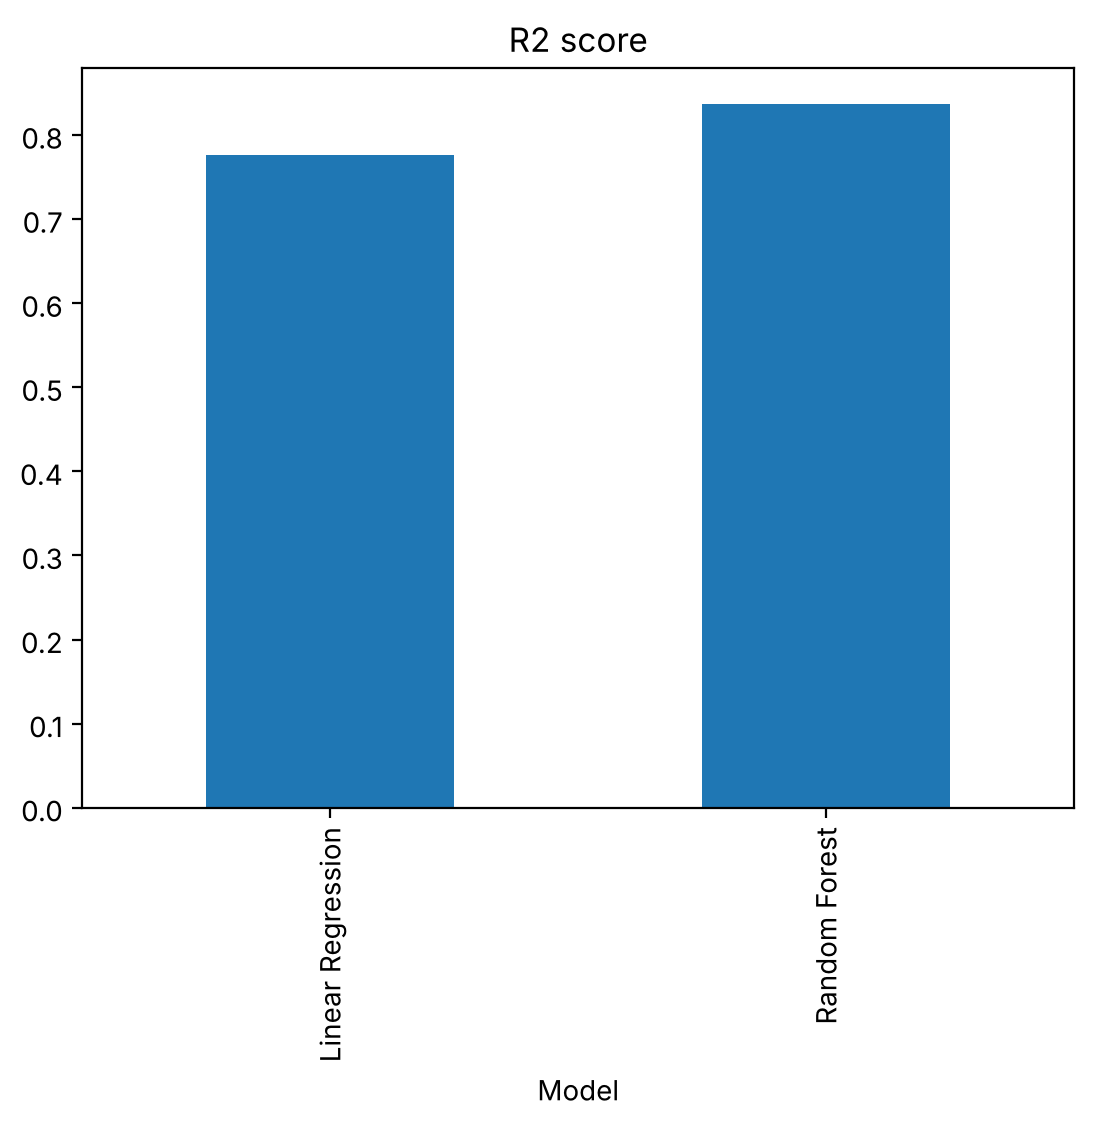

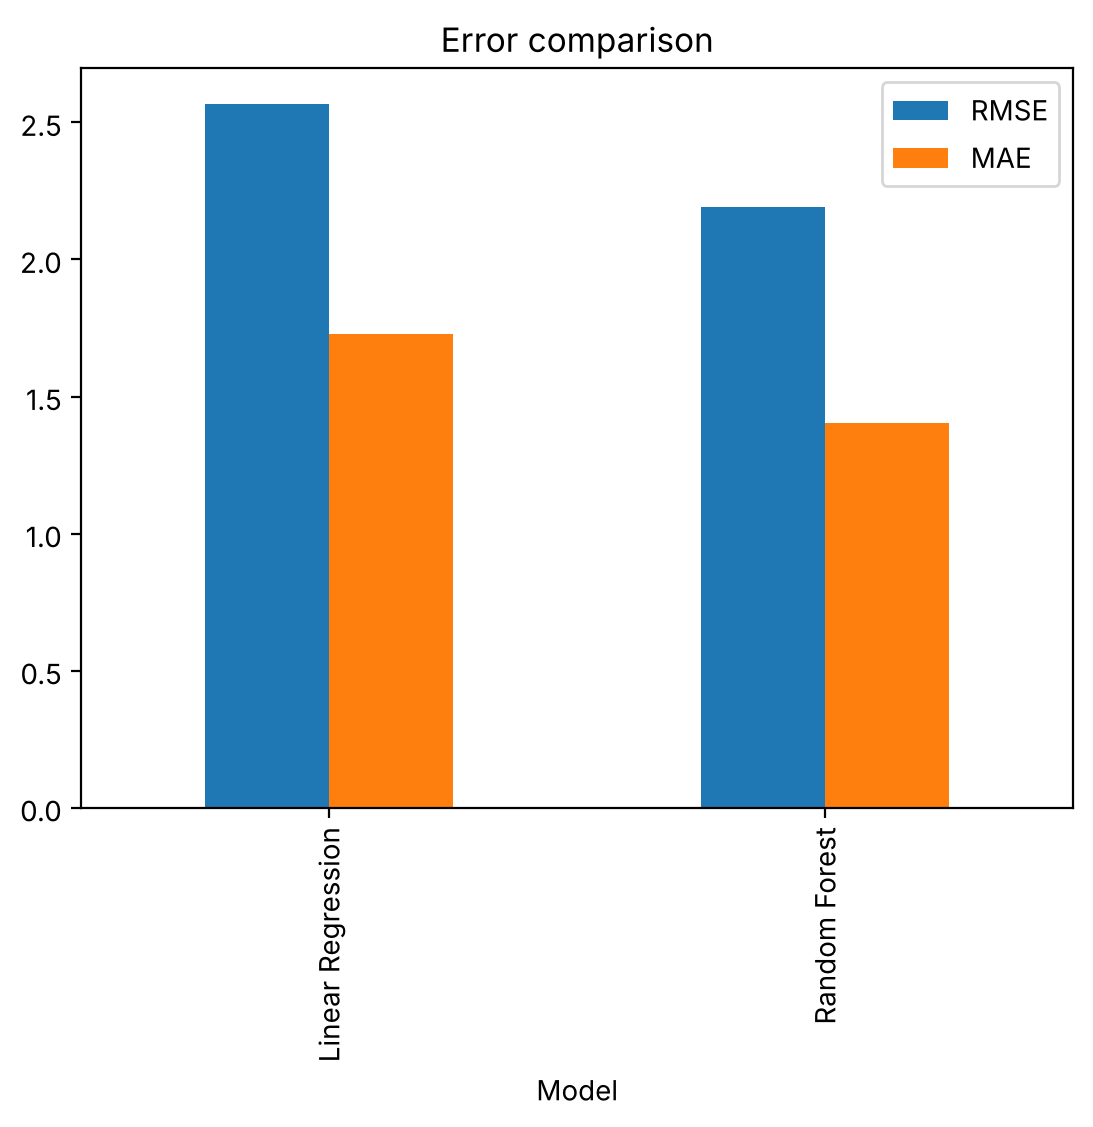

In [16]:
def scores(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"Model": name, "R2": r2_score(y_true, y_pred), "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mse, "RMSE": np.sqrt(mse)}

results = pd.DataFrame([scores("Linear Regression", y_test, lr_pred),
                        scores("Random Forest", y_test, rf_pred)]).set_index("Model")
print(results.round(4))
results[["R2"]].plot(kind="bar", legend=False, title="R2 score"); plt.show()
results[["RMSE", "MAE"]].plot(kind="bar", title="Error comparison"); plt.show()

In [17]:
best = results['R2'].idxmax()
print(f"{best} performs better (higher R2 and lower RMSE).")

Random Forest performs better (higher R2 and lower RMSE).
